# 21. Trust Scorer v2 (`score_trust`): Step 6.2b Retraining on Corrected Labels & Pre-Registered Evaluation

**Purpose**: Retrain and evaluate the submission-time complaint trust scorer `LogisticRegression(class_weight='balanced')` on the standardized Step 6.1d labels (`src/models/trust_label_rules.csv`, zero DEP/NYPD rule conflicts), apply three pre-registered decision rules (`R1`, `R2`, `R3`) on a strict chronological 80/20 split (`created < 2026-09-01 00:16:13`), benchmark ablations (`A`–`E`), noise within-agency slices (`NYPD` vs `DEP`), sensitivities (`S1`–`S4`), and probability calibration (`prior_shift`), and freeze the chosen model bundle to `models/trust_model.joblib`.

- **Inputs**:
  - `data/processed/complaints_clean.csv` (236,507 Brooklyn 311 complaints, 2025-11 to 2026-10)
  - `data/processed/resolution_lookup.csv` (152 normalized 311 resolution descriptions)
  - `src/models/trust_label_rules.csv` (37 single-label substring rules)
- **Outputs**:
  - `models/trust_model.joblib` (overwritten frozen trust scorer bundle with 15 schema fields & rules SHA-256)
  - `report/figures/21_m1_vs_m2_roc_pr.png`
  - `report/figures/21_ablations_agency_sensitivities.png`
  - `report/figures/21_reliability_raw_vs_shifted.png`
- **Runtime**: ~90–120 seconds (including 1,000-resample bootstrap CIs and S1–S4 re-fits)

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

from src.nbutils import Checker
from src.models.trust import (
    TRUST_CATEGORICAL_COLS,
    TRUST_NUMERIC_COLS,
    TRUST_RULES_PATH,
    NEARBY_PRIOR_DEFINITION,
    assign_trust_labels,
    build_trust_features,
    classify_noise_valid_text_group,
    compute_calibration_table,
    compute_file_sha256,
    compute_nearby_prior_24h_200m,
    evaluate_ablation_suite,
    evaluate_noise_agency_slices,
    evaluate_sensitivity_suite,
    evaluate_with_ci_and_bss,
    load_trust_model,
    prior_shift,
    save_trust_model,
    score_trust,
    select_top_noise_coords,
    train_trust_model,
)

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 260)
pd.set_option("display.max_colwidth", 100)

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section 0 & (a): PRE-REGISTERED RULES (printed before any result), Causal Feature, Split & Table (a)
print("=== PRE-REGISTERED DECISION RULES (DECIDED A PRIORI BEFORE ANY RESULT) ===")
print("R1 (Group Usability): A group is usable iff the 95% percentile bootstrap lower bound of its ROC AUC")
print("    (M2, evaluated on that group's own test rows, 1,000 resamples, seed=42) >= 0.65")
print("    AND test valid >= 50 AND test invalid >= 50.")
print("R2 (Model Variant M2 vs M1): Shipped model is M2 (top-5 noise training coordinates removed from TRAIN),")
print("    chosen a priori on causal grounds, UNLESS M2's ROC AUC on the noise test slice excluding those")
print("    same 5 coordinates is lower than M1's by > 0.01, in which case ship M1.")
print("R3 (Prior-Shift Calibration): Ship the prior-shifted probability prior_shift(p, logit_shift) = sigmoid(logit(p) + logit_shift)")
print("    with logit_shift = log(n_valid_train / n_invalid_train) of the shipped labelled pooled train rows")
print("    iff the pooled Brier score over R1-usable groups' test rows is at least 10% lower than raw")
print("    (brier_shifted <= 0.90 * brier_raw); otherwise ship raw unshifted probabilities.")
print()
print("=== EXACT NEARBY PRIOR FEATURE DEFINITION ===")
print(NEARBY_PRIOR_DEFINITION)
print()

t_start = time.time()
complaints_df = pd.read_csv(
    ROOT / "data/processed/complaints_clean.csv",
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)
lookup_df = pd.read_csv(
    ROOT / "data/processed/resolution_lookup.csv",
    dtype={"resolution_id": str},
    keep_default_na=False,
)

complaints_df["ts"] = pd.to_datetime(complaints_df["timestamp"])
complaints_df["trust_label"] = assign_trust_labels(complaints_df, lookup_df=lookup_df, apply_gate=True)

t0 = time.time()
complaints_df["nearby_prior_24h_200m"] = compute_nearby_prior_24h_200m(complaints_df)
print(f"Loaded {len(complaints_df):,} rows; computed causal nearby_prior_24h_200m in {time.time() - t0:.2f}s.")

# Verify zero-mismatch causality against brute force on 100 random rows (seed=42)
sample_100 = complaints_df.sample(n=100, random_state=42)
brute_mismatches = 0
for _, sr in sample_100.iterrows():
    s_ts = sr["ts"]
    cands = complaints_df[(complaints_df["ts"] >= s_ts - pd.Timedelta(hours=24)) & (complaints_df["ts"] < s_ts)]
    d2 = (cands["x_m"] - sr["x_m"]) ** 2 + (cands["y_m"] - sr["y_m"]) ** 2
    if int((d2 <= 200.0 ** 2).sum()) != int(sr["nearby_prior_24h_200m"]):
        brute_mismatches += 1
print(f"Causal brute-force spot check (100 rows, seed=42) mismatches: {brute_mismatches}")

# Chronological 80/20 split by created timestamp
cutoff_ts = pd.Timestamp("2026-09-01 00:16:13")
train_all = complaints_df[complaints_df["ts"] < cutoff_ts].copy()
test_all = complaints_df[complaints_df["ts"] >= cutoff_ts].copy()

train_lab = train_all[train_all["trust_label"].isin(["valid", "invalid"])].copy()
test_lab = test_all[test_all["trust_label"].isin(["valid", "invalid"])].copy()
train_lab["y"] = (train_lab["trust_label"] == "valid").astype(int)
test_lab["y"] = (test_lab["trust_label"] == "valid").astype(int)

groups_order = ["flood", "noise", "road", "sewer_backup"]
eval_groups_order = ["noise", "road", "flood", "sewer_backup"]

# Table (a): Train & Test labelled (and excluded) counts per group (must match Notebook 20)
rows_a = []
for g in groups_order + ["ALL"]:
    gtr = train_all if g == "ALL" else train_all[train_all["group"] == g]
    gte = test_all if g == "ALL" else test_all[test_all["group"] == g]
    tr_v = int((gtr["trust_label"] == "valid").sum())
    tr_i = int((gtr["trust_label"] == "invalid").sum())
    tr_e = int((gtr["trust_label"] == "excluded").sum())
    te_v = int((gte["trust_label"] == "valid").sum())
    te_i = int((gte["trust_label"] == "invalid").sum())
    te_e = int((gte["trust_label"] == "excluded").sum())
    rows_a.append({
        "group": g,
        "train_valid": tr_v,
        "train_invalid": tr_i,
        "train_labelled": tr_v + tr_i,
        "train_excluded": tr_e,
        "test_valid": te_v,
        "test_invalid": te_i,
        "test_labelled": te_v + te_i,
        "test_excluded": te_e,
    })

table_a_df = pd.DataFrame(rows_a)
print(f"\n=== (a) Chronological Split (created < {cutoff_ts}) Label Counts per Group ===")
print(table_a_df.to_string(index=False))


=== PRE-REGISTERED DECISION RULES (DECIDED A PRIORI BEFORE ANY RESULT) ===
R1 (Group Usability): A group is usable iff the 95% percentile bootstrap lower bound of its ROC AUC
    (M2, evaluated on that group's own test rows, 1,000 resamples, seed=42) >= 0.65
    AND test valid >= 50 AND test invalid >= 50.
R2 (Model Variant M2 vs M1): Shipped model is M2 (top-5 noise training coordinates removed from TRAIN),
    chosen a priori on causal grounds, UNLESS M2's ROC AUC on the noise test slice excluding those
    same 5 coordinates is lower than M1's by > 0.01, in which case ship M1.
R3 (Prior-Shift Calibration): Ship the prior-shifted probability prior_shift(p, logit_shift) = sigmoid(logit(p) + logit_shift)
    with logit_shift = log(n_valid_train / n_invalid_train) of the shipped labelled pooled train rows
    iff the pooled Brier score over R1-usable groups' test rows is at least 10% lower than raw
    (brier_shifted <= 0.90 * brier_raw); otherwise ship raw unshifted probabilities.

===

Loaded 236,507 rows; computed causal nearby_prior_24h_200m in 9.83s.


Causal brute-force spot check (100 rows, seed=42) mismatches: 0



=== (a) Chronological Split (created < 2026-09-01 00:16:13) Label Counts per Group ===
       group  train_valid  train_invalid  train_labelled  train_excluded  test_valid  test_invalid  test_labelled  test_excluded
       flood         2124           1085            3209            1503         318           136            454            354
       noise         5191          85857           91048           77208         680         21973          22653          20934
        road         4934           1993            6927            6731         718           331           1049           1431
sewer_backup          554           1162            1716             863          39           218            257            170
         ALL        12803          90097          102900           86305        1755         22658          24413          22889


=== Top-5 Noise Coordinates (Defined From TRAIN Noise Rows Only) ===
           address       lat        lon  train_total  train_valid  train_invalid  test_total  test_labelled
    1869 83 STREET 40.608101 -73.999384         6868            7           6779        1976           1935
   177 SAND STREET 40.699800 -73.983616         1583            8           1395         322            311
   203 HULL STREET 40.679775 -73.908893         1111            6            713          29             21
295 ST JOHNS PLACE 40.674188 -73.967832          866            0              7         103              2
      85 NAVY WALK 40.695482 -73.980649          809            6            457         372            229



M1 fitted on 102,900 labelled train rows (80 features); coef(nearby_prior_24h_200m) = -0.01213
M2 fitted on 93,522 labelled train rows (80 features); coef(nearby_prior_24h_200m) = +0.04484



=== (b) M1 vs M2 Test Performance (1,000 Bootstrap Resamples, Seed=42, 10 Equal-Width ECE Bins) ===
model           slice  n_test  n_valid  n_invalid test_base_rate roc_auc roc_ci_low roc_ci_high pr_auc pr_ci_low pr_ci_high  brier brier_const     bss    ece mean_pred
   M1           noise   22653      680      21973         0.0300  0.7764     0.7584      0.7934 0.3083    0.2696     0.3459 0.0894      0.0298 -1.9938 0.2374    0.2674
   M1            road    1049      718        331         0.6845  0.9385     0.9171      0.9552 0.9577    0.9392     0.9738 0.1308      0.2167 +0.3967 0.1672    0.8516
   M1           flood     454      318        136         0.7004  0.7369     0.6837      0.7895 0.8393    0.7904     0.8857 0.2467      0.2113 -0.1674 0.2357    0.9361
   M1    sewer_backup     257       39        218         0.1518  0.4656     0.3568      0.5719 0.1885    0.1149     0.2954 0.5908      0.1580 -2.7391 0.6775    0.8285
   M1          POOLED   24413     1755      22658         0

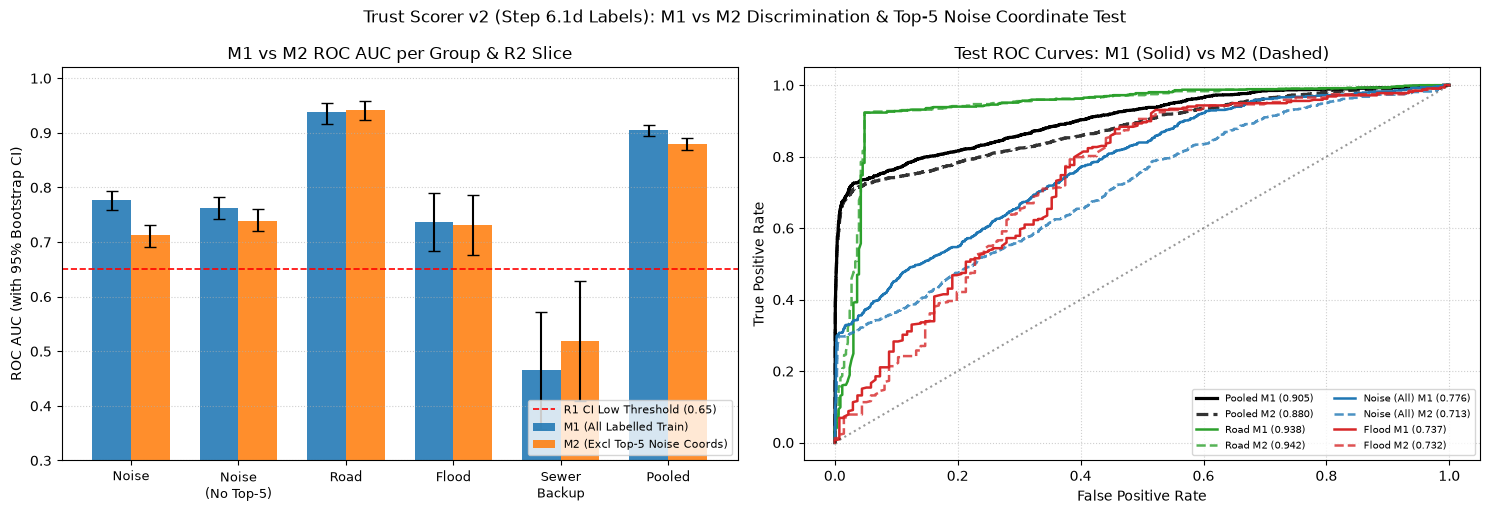

Saved: report/figures/21_m1_vs_m2_roc_pr.png


In [3]:
# Section (b): M1 (All Labelled Train) vs M2 (Top-5 Noise Train Coords Removed) + Full Metrics & 95% CIs
# Define Top-5 noise coordinates STRICTLY from TRAIN noise rows only (zero test leakage)
top5_records, top5_coords = select_top_noise_coords(train_all, top_k=5, label_col="trust_label")
top5_df = pd.DataFrame(top5_records)

# Add test counts at those exact 5 coordinates for inspection only
te_noise_all = test_all[test_all["group"] == "noise"]
te_noise_lab = test_lab[test_lab["group"] == "noise"]
top5_df["test_total"] = [
    int(((te_noise_all["x_m"] == r["x_m"]) & (te_noise_all["y_m"] == r["y_m"])).sum())
    for r in top5_records
]
top5_df["test_labelled"] = [
    int(((te_noise_lab["x_m"] == r["x_m"]) & (te_noise_lab["y_m"] == r["y_m"])).sum())
    for r in top5_records
]
print("=== Top-5 Noise Coordinates (Defined From TRAIN Noise Rows Only) ===")
print(top5_df[["address", "lat", "lon", "train_total", "train_valid", "train_invalid", "test_total", "test_labelled"]].to_string(index=False))

tr_coord_series = pd.Series(list(zip(train_lab["x_m"], train_lab["y_m"])), index=train_lab.index)
te_coord_series = pd.Series(list(zip(test_lab["x_m"], test_lab["y_m"])), index=test_lab.index)
tr_is_top5_noise = (train_lab["group"] == "noise") & tr_coord_series.isin(top5_coords)
te_is_top5_noise = (test_lab["group"] == "noise") & te_coord_series.isin(top5_coords)

m1_train_lab = train_lab.copy()
m2_train_lab = train_lab[~tr_is_top5_noise].copy()

# Fit M1 ONLY on labelled train rows
X_m1_tr, enc_m1 = build_trust_features(m1_train_lab, return_encoder=True)
clf_m1 = train_trust_model(X_m1_tr, m1_train_lab["y"])
X_m1_te = build_trust_features(test_lab, encoder=enc_m1)
p1_te = np.clip(clf_m1.predict_proba(X_m1_te)[:, 1].astype(float), 0.0, 1.0)

# Fit M2 ONLY on labelled train rows with top-5 noise coordinates removed
X_m2_tr, enc_m2 = build_trust_features(m2_train_lab, return_encoder=True)
clf_m2 = train_trust_model(X_m2_tr, m2_train_lab["y"])
X_m2_te = build_trust_features(test_lab, encoder=enc_m2)
p2_te = np.clip(clf_m2.predict_proba(X_m2_te)[:, 1].astype(float), 0.0, 1.0)

coef_m1_nearby = float(clf_m1.coef_[0, list(X_m1_tr.columns).index("nearby_prior_24h_200m")])
coef_m2_nearby = float(clf_m2.coef_[0, list(X_m2_tr.columns).index("nearby_prior_24h_200m")])
print(f"\nM1 fitted on {len(m1_train_lab):,} labelled train rows ({X_m1_tr.shape[1]} features); coef(nearby_prior_24h_200m) = {coef_m1_nearby:+.5f}")
print(f"M2 fitted on {len(m2_train_lab):,} labelled train rows ({X_m2_tr.shape[1]} features); coef(nearby_prior_24h_200m) = {coef_m2_nearby:+.5f}")

# Evaluate M1 and M2 per group (noise, road, flood, sewer_backup), POOLED, and noise_excl_top5
def eval_model_table(model_name, p_te, tr_df_ref):
    out_rows = []
    metric_dict = {}
    slice_specs = [(g, (test_lab["group"].to_numpy() == g), tr_df_ref[tr_df_ref["group"] == g]) for g in eval_groups_order]
    slice_specs.append(("POOLED", np.ones(len(test_lab), dtype=bool), tr_df_ref))
    slice_specs.append(("noise_excl_top5", ((test_lab["group"] == "noise") & (~te_is_top5_noise)).to_numpy(), tr_df_ref[tr_df_ref["group"] == "noise"]))
    for s_name, te_mask, tr_sub in slice_specs:
        tr_rate = float(tr_sub["y"].mean())
        ev = evaluate_with_ci_and_bss(
            test_lab.loc[te_mask, "y"],
            p_te[te_mask],
            train_base_rate=tr_rate,
            n_boot=1000,
            seed=42,
            n_bins=10,
        )
        ev_row = {"model": model_name, "slice": s_name, **ev}
        out_rows.append(ev_row)
        metric_dict[s_name] = ev_row
    return pd.DataFrame(out_rows), metric_dict

m1_eval_df, m1_metrics = eval_model_table("M1", p1_te, m1_train_lab)
m2_eval_df, m2_metrics = eval_model_table("M2", p2_te, m2_train_lab)
b_table_df = pd.concat([m1_eval_df, m2_eval_df], ignore_index=True)

fmt_b = {
    "test_base_rate": "{:.4f}".format,
    "train_base_rate": "{:.4f}".format,
    "roc_auc": "{:.4f}".format,
    "roc_ci_low": "{:.4f}".format,
    "roc_ci_high": "{:.4f}".format,
    "pr_auc": "{:.4f}".format,
    "pr_ci_low": "{:.4f}".format,
    "pr_ci_high": "{:.4f}".format,
    "brier": "{:.4f}".format,
    "brier_const": "{:.4f}".format,
    "bss": "{:+.4f}".format,
    "ece": "{:.4f}".format,
    "mean_pred": "{:.4f}".format,
}
cols_b = [
    "model", "slice", "n_test", "n_valid", "n_invalid", "test_base_rate",
    "roc_auc", "roc_ci_low", "roc_ci_high", "pr_auc", "pr_ci_low", "pr_ci_high",
    "brier", "brier_const", "bss", "ece", "mean_pred",
]
print("\n=== (b) M1 vs M2 Test Performance (1,000 Bootstrap Resamples, Seed=42, 10 Equal-Width ECE Bins) ===")
print(b_table_df[cols_b].to_string(index=False, formatters=fmt_b))

# Figure 1: M1 vs M2 ROC AUC with 95% CIs and ROC Curves
fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot_slices = ["noise", "noise_excl_top5", "road", "flood", "sewer_backup", "POOLED"]
x_idx = np.arange(len(plot_slices))
w = 0.36

m1_vals = [m1_metrics[s]["roc_auc"] for s in plot_slices]
m1_err_lo = [m1_metrics[s]["roc_auc"] - m1_metrics[s]["roc_ci_low"] for s in plot_slices]
m1_err_hi = [m1_metrics[s]["roc_ci_high"] - m1_metrics[s]["roc_auc"] for s in plot_slices]
m2_vals = [m2_metrics[s]["roc_auc"] for s in plot_slices]
m2_err_lo = [m2_metrics[s]["roc_auc"] - m2_metrics[s]["roc_ci_low"] for s in plot_slices]
m2_err_hi = [m2_metrics[s]["roc_ci_high"] - m2_metrics[s]["roc_auc"] for s in plot_slices]

axes[0].bar(x_idx - w/2, m1_vals, w, yerr=[m1_err_lo, m1_err_hi], capsize=4, label="M1 (All Labelled Train)", color="#1f77b4", alpha=0.88)
axes[0].bar(x_idx + w/2, m2_vals, w, yerr=[m2_err_lo, m2_err_hi], capsize=4, label="M2 (Excl Top-5 Noise Coords)", color="#ff7f0e", alpha=0.88)
axes[0].axhline(0.65, color="red", linestyle="--", lw=1.2, label="R1 CI Low Threshold (0.65)")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(["Noise", "Noise\n(No Top-5)", "Road", "Flood", "Sewer\nBackup", "Pooled"], fontsize=9)
axes[0].set_ylim(0.3, 1.02)
axes[0].set_ylabel("ROC AUC (with 95% Bootstrap CI)")
axes[0].set_title("M1 vs M2 ROC AUC per Group & R2 Slice")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(True, axis="y", linestyle=":", alpha=0.6)

curve_specs = [
    ("POOLED", "Pooled", "black", 2.3),
    ("road", "Road", "#2ca02c", 1.8),
    ("noise", "Noise (All)", "#1f77b4", 1.8),
    ("flood", "Flood", "#d62728", 1.8),
]
for g_k, g_l, col, lw in curve_specs:
    mk = np.ones(len(test_lab), dtype=bool) if g_k == "POOLED" else (test_lab["group"].to_numpy() == g_k)
    yt = test_lab.loc[mk, "y"].to_numpy()
    fpr1, tpr1, _ = roc_curve(yt, p1_te[mk])
    fpr2, tpr2, _ = roc_curve(yt, p2_te[mk])
    axes[1].plot(fpr1, tpr1, color=col, lw=lw, linestyle="-", label=f"{g_l} M1 ({m1_metrics[g_k]['roc_auc']:.3f})")
    axes[1].plot(fpr2, tpr2, color=col, lw=lw, linestyle="--", alpha=0.8, label=f"{g_l} M2 ({m2_metrics[g_k]['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k:", alpha=0.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Test ROC Curves: M1 (Solid) vs M2 (Dashed)")
axes[1].legend(fontsize=7.5, loc="lower right", ncol=2)
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle("Trust Scorer v2 (Step 6.1d Labels): M1 vs M2 Discrimination & Top-5 Noise Coordinate Test", fontsize=12)
plt.tight_layout()
fig1_path = fig_dir / "21_m1_vs_m2_roc_pr.png"
fig.savefig(fig1_path, dpi=150)
plt.show()
print(f"Saved: {fig1_path.relative_to(ROOT).as_posix()}")


=== (c) M2 Feature Ablations (Per-Group & Pooled Test ROC AUC) ===
                                            ablation  n_features  noise   road  flood sewer_backup POOLED
                                             A: full          80 0.7129 0.9423 0.7322       0.5188 0.8802
           B: complaint_type + descriptor_group only          27 0.7531 0.9445 0.7052       0.5000 0.8968
                 C: full minus nearby_prior_24h_200m          79 0.7691 0.9390 0.7384       0.4797 0.9023
      D: without complaint_type and descriptor_group          53 0.6819 0.9280 0.7019       0.5329 0.8635
E: complaint_type train valid-rate lookup (no model)           1 0.7421 0.5000 0.5000       0.5000 0.8838



=== (d1) M2 Noise Within-Agency Slices (Evaluation on Test Noise Rows) ===
agency  n_test  n_valid  n_invalid test_base_rate roc_auc pr_auc
  NYPD   20465      382      20083         0.0187  0.5929 0.0221
   DEP    2188      298       1890         0.1362  0.8681 0.6540

=== (d2) Valid Noise Composition by Agency/Action Text Group ===
            text_group  train  test  total test_share_pct
           NYPD action   2341     0   2341          0.00%
          NYPD summons   1563   330   1893         48.53%
     dog letters (DEP)    686   202    888         29.71%
           DEP summons    359    95    454         13.97%
           NYPD arrest    242    52    294          7.65%
DEP catch basin debris      0     1      1          0.15%



=== (e) M2 Sensitivities (Base, S1, S2, S3, S4): Per-Group ROC AUC, PR AUC, Test Base Rate ===
sensitivity        group  n_test  n_valid  n_invalid base_rate roc_auc pr_auc
       Base        noise   22653      680      21973    0.0300  0.7129 0.2410
       Base         road    1049      718        331    0.6845  0.9423 0.9638
       Base        flood     454      318        136    0.7004  0.7322 0.8280
       Base sewer_backup     257       39        218    0.1518  0.5188 0.2404
       Base       POOLED   24413     1755      22658    0.0719  0.8802 0.7201
         S1        noise   37766      680      37086    0.0180  0.7289 0.2813
         S1         road    1049      718        331    0.6845  0.9414 0.9614
         S1        flood     454      318        136    0.7004  0.7319 0.8354
         S1 sewer_backup     257       39        218    0.1518  0.5119 0.2312
         S1       POOLED   39526     1755      37771    0.0444  0.8904 0.7213
         S2        noise   37766    15793     

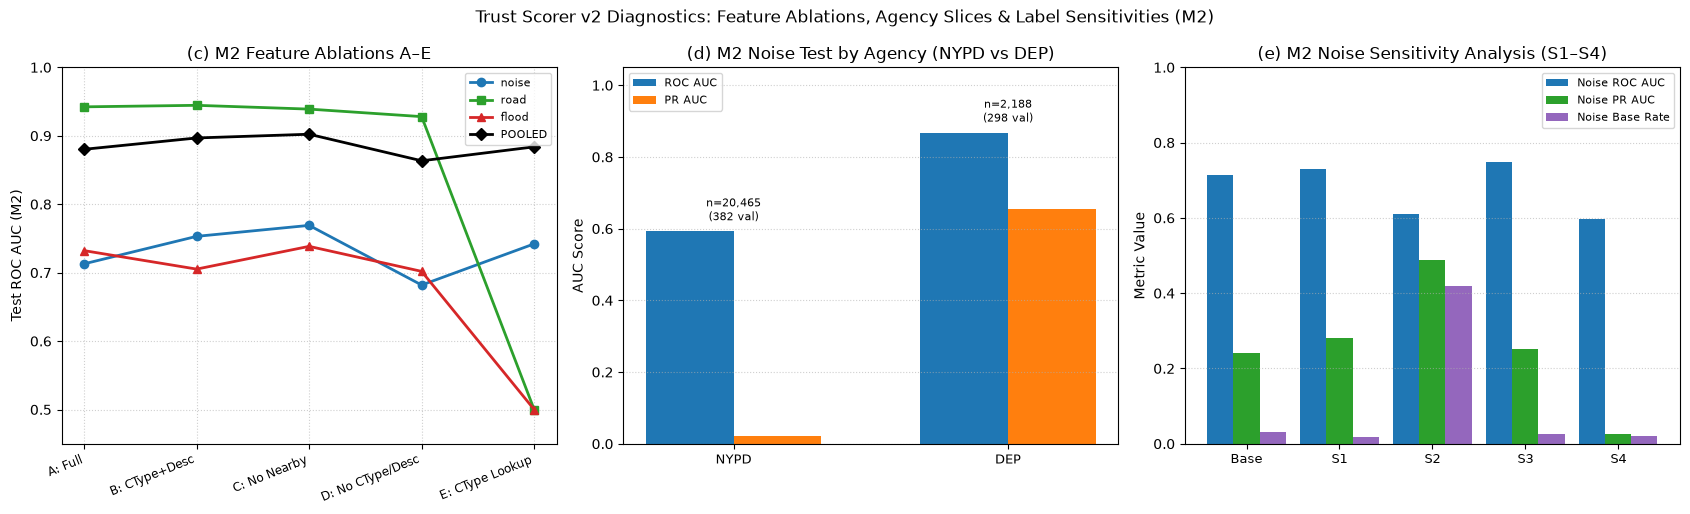

Saved: report/figures/21_ablations_agency_sensitivities.png


In [4]:
# Sections (c), (d), (e): M2 Ablations, Noise Agency Slices & Valid Composition, and S1–S4 Sensitivities
# (c) Feature ablations on M2 (fit strictly on m2_train_lab, evaluated on test_lab)
ablation_df = evaluate_ablation_suite(
    m2_train_lab,
    test_lab,
    label_col="trust_label",
    group_col="group",
    groups=eval_groups_order,
)
print("=== (c) M2 Feature Ablations (Per-Group & Pooled Test ROC AUC) ===")
print(ablation_df.to_string(index=False, formatters={
    g: "{:.4f}".format for g in eval_groups_order + ["POOLED"]
}))

# (d) Noise within-agency slices for M2 + Valid composition by text group
noise_test_df = test_lab[test_lab["group"] == "noise"].copy()
p2_noise_test = p2_te[test_lab["group"].to_numpy() == "noise"]
agency_df = evaluate_noise_agency_slices(noise_test_df, p2_noise_test, lookup_df=lookup_df, y_col="y")
print("\n=== (d1) M2 Noise Within-Agency Slices (Evaluation on Test Noise Rows) ===")
print(agency_df.to_string(index=False, formatters={
    "test_base_rate": "{:.4f}".format,
    "roc_auc": "{:.4f}".format,
    "pr_auc": "{:.4f}".format,
}))

lkp_map = dict(zip(lookup_df["resolution_id"].astype(str), lookup_df["text"]))
noise_valid_all = complaints_df[(complaints_df["group"] == "noise") & (complaints_df["trust_label"] == "valid")].copy()
noise_valid_all["split"] = np.where(noise_valid_all["ts"] < cutoff_ts, "train", "test")
noise_valid_all["text_group"] = noise_valid_all["resolution_id"].map(lkp_map).map(classify_noise_valid_text_group)
noise_comp_tbl = pd.crosstab(noise_valid_all["text_group"], noise_valid_all["split"])
for sp in ["train", "test"]:
    if sp not in noise_comp_tbl.columns:
        noise_comp_tbl[sp] = 0
noise_comp_tbl = noise_comp_tbl[["train", "test"]].copy()
noise_comp_tbl["total"] = noise_comp_tbl["train"] + noise_comp_tbl["test"]
noise_comp_tbl["test_share_pct"] = (noise_comp_tbl["test"] / max(int(noise_comp_tbl["test"].sum()), 1)) * 100.0
noise_comp_tbl = noise_comp_tbl.sort_values("total", ascending=False).reset_index()
print("\n=== (d2) Valid Noise Composition by Agency/Action Text Group ===")
print(noise_comp_tbl.to_string(index=False, formatters={"test_share_pct": "{:.2f}%".format}))

# (e) Sensitivities S1..S4 on M2 (plus Base reference)
sens_df = evaluate_sensitivity_suite(
    complaints_df,
    train_cutoff_ts=cutoff_ts,
    top5_noise_coords=top5_coords,
    lookup_df=lookup_df,
    sensitivities=(None, "S1", "S2", "S3", "S4"),
    groups=eval_groups_order,
)
print("\n=== (e) M2 Sensitivities (Base, S1, S2, S3, S4): Per-Group ROC AUC, PR AUC, Test Base Rate ===")
print(sens_df.to_string(index=False, formatters={
    "base_rate": "{:.4f}".format,
    "roc_auc": "{:.4f}".format,
    "pr_auc": "{:.4f}".format,
}))

# Figure 2: Ablations, Noise Agency Slices & Valid Composition, and Sensitivities S1..S4
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# Panel A: M2 Ablations ROC AUC
ab_short = ["A: Full", "B: CType+Desc", "C: No Nearby", "D: No CType/Desc", "E: CType Lookup"]
xa = np.arange(len(ab_short))
for g, col, mk in [("noise", "#1f77b4", "o"), ("road", "#2ca02c", "s"), ("flood", "#d62728", "^"), ("POOLED", "black", "D")]:
    axes[0].plot(xa, ablation_df[g].values, marker=mk, lw=2, color=col, label=g)
axes[0].set_xticks(xa)
axes[0].set_xticklabels(ab_short, rotation=22, ha="right", fontsize=8.5)
axes[0].set_ylim(0.45, 1.0)
axes[0].set_ylabel("Test ROC AUC (M2)")
axes[0].set_title("(c) M2 Feature Ablations A–E")
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel B: Noise Within-Agency Performance (NYPD vs DEP)
ag_x = np.arange(len(agency_df))
aw = 0.32
axes[1].bar(ag_x - aw/2, agency_df["roc_auc"], aw, label="ROC AUC", color="#1f77b4")
axes[1].bar(ag_x + aw/2, agency_df["pr_auc"], aw, label="PR AUC", color="#ff7f0e")
for idx_ag, r_ag in agency_df.iterrows():
    axes[1].text(idx_ag, max(r_ag["roc_auc"], r_ag["pr_auc"]) + 0.02,
                 f"n={int(r_ag['n_test']):,}\n({int(r_ag['n_valid'])} val)",
                 ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(ag_x)
axes[1].set_xticklabels(agency_df["agency"], fontsize=9.5)
axes[1].set_ylim(0.0, 1.05)
axes[1].set_ylabel("AUC Score")
axes[1].set_title("(d) M2 Noise Test by Agency (NYPD vs DEP)")
axes[1].legend(fontsize=8)
axes[1].grid(True, axis="y", linestyle=":", alpha=0.6)

# Panel C: Sensitivities S1..S4 Noise Impact
sens_noise = sens_df[sens_df["group"] == "noise"].reset_index(drop=True)
xs = np.arange(len(sens_noise))
sw = 0.28
axes[2].bar(xs - sw, sens_noise["roc_auc"], sw, label="Noise ROC AUC", color="#1f77b4")
axes[2].bar(xs, sens_noise["pr_auc"], sw, label="Noise PR AUC", color="#2ca02c")
axes[2].bar(xs + sw, sens_noise["base_rate"], sw, label="Noise Base Rate", color="#9467bd")
axes[2].set_xticks(xs)
axes[2].set_xticklabels(sens_noise["sensitivity"], fontsize=9)
axes[2].set_ylim(0.0, 1.0)
axes[2].set_ylabel("Metric Value")
axes[2].set_title("(e) M2 Noise Sensitivity Analysis (S1–S4)")
axes[2].legend(fontsize=8)
axes[2].grid(True, axis="y", linestyle=":", alpha=0.6)

fig.suptitle("Trust Scorer v2 Diagnostics: Feature Ablations, Agency Slices & Label Sensitivities (M2)", fontsize=12)
plt.tight_layout()
fig2_path = fig_dir / "21_ablations_agency_sensitivities.png"
fig.savefig(fig2_path, dpi=150)
plt.show()
print(f"Saved: {fig2_path.relative_to(ROOT).as_posix()}")


=== (f) 10-Bin Reliability Tables per Usable Group (Shipped M1: Raw vs Prior-Shifted, logit_shift=-1.951207) ===

--- Group: noise | RAW (ECE=0.2374, Brier=0.0894) vs PRIOR-SHIFTED (ECE=0.0322, Brier=0.0243) ---
 bin_range  n_raw  mean_pred_raw  obs_rate_raw  n_shifted  mean_pred_shifted  obs_rate_shifted
[0.0, 0.1)   2063         0.0718        0.0058      21092             0.0469            0.0198
[0.1, 0.2)   5191         0.1491        0.0042       1294             0.1227            0.0471
[0.2, 0.3)   6614         0.2551        0.0213          2             0.2062            0.0000
[0.3, 0.4)   6073         0.3449        0.0303          6             0.3767            0.6667
[0.4, 0.5)   1992         0.4370        0.0487         71             0.4671            0.7042
[0.5, 0.6)    409         0.5376        0.0489        134             0.5411            0.7687
[0.6, 0.7)     46         0.6130        0.0435         41             0.6333            0.8537
[0.7, 0.8)      0           

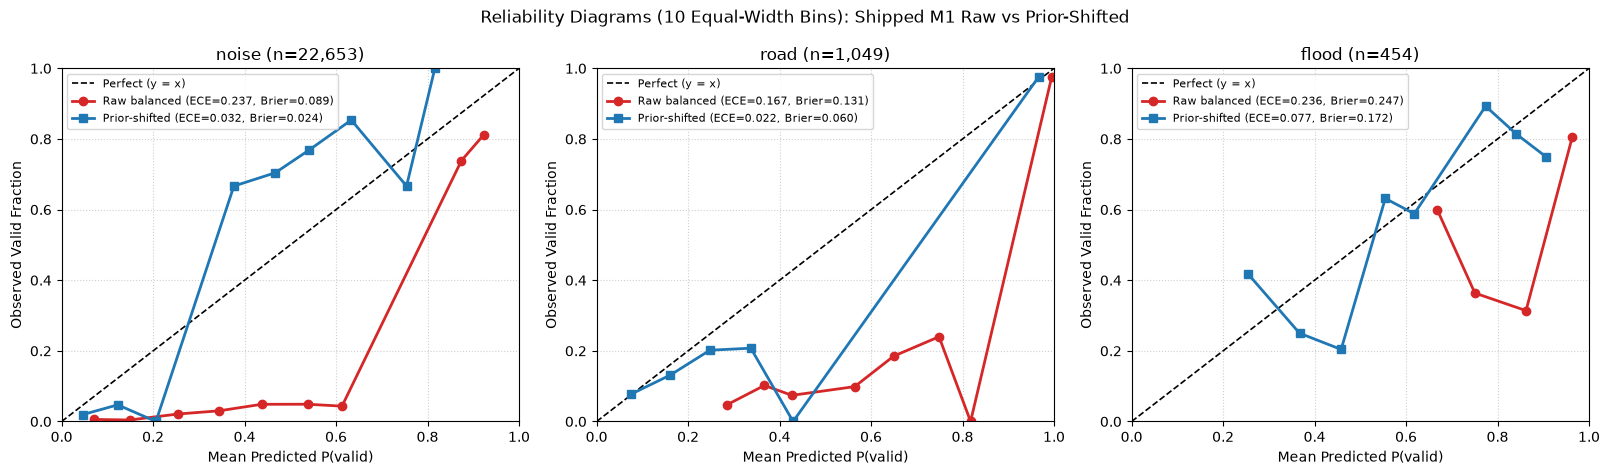

Saved: report/figures/21_reliability_raw_vs_shifted.png

=== (g) PRE-REGISTERED RULES VERDICTS ===
R1 (Group Usability on M2, 95% bootstrap CI low >= 0.65 AND valid >= 50 AND invalid >= 50):
       group M2_roc_auc M2_ci_low  n_valid_test  n_invalid_test  ci_low_ge_0.65  valid_ge_50  invalid_ge_50  R1_usable
       noise     0.7129    0.6918           680           21973            True         True           True       True
        road     0.9423    0.9227           718             331            True         True           True       True
       flood     0.7322    0.6754           318             136            True         True           True       True
sewer_backup     0.5188    0.4088            39             218           False        False           True      False
R1 VERDICT -> usable_groups = ['noise', 'road', 'flood'] (sewer_backup excluded: ci_low=0.4088 < 0.65 and test valid=39 < 50).

R2 VERDICT -> SHIP M1 (fallback triggered: M2 noise_excl_top5 ROC AUC 0.7389 is lower 


Saved overwritten bundle: models/trust_model.joblib (sha256=161db692d16cbc53fd9234d062341444d0a2a5f5e553e7424092fdfe25e4f64f)
Bundle variant=M1, calibrated=True, logit_shift=-1.951207, usable_groups=['noise', 'road', 'flood']
Bundle group_train_valid_rate={'flood': 0.6619, 'noise': 0.057, 'road': 0.7123, 'sewer_backup': 0.3228}


Verified score_trust on all test rows (n=47,302): min=0.000116, max=0.984146, NaNs=0; labelled max diff vs direct fit=0.00e+00

=== (h) Sample score_trust Predictions ===
                                   sample               complaint_type    descriptor_group  hour  weekday  nearby_24h score_trust_shipped raw_balanced_prob
1. noise music Saturday hour 23 nearby 10          Noise - Residential         music_party    23        5          10              0.0688            0.3422
  2. road pothole weekday hour 9 nearby 0             Street Condition             pothole     9        2           0              0.9711            0.9958
     3. flood (Sewer catch_basin_clogged)                        Sewer catch_basin_clogged    14        3           1              0.7475            0.9542
    4. sewer_backup (non-usable under R1)                        Sewer              backup    14        3           0              0.2424            0.6925
                 5. unseen complaint_type Unseen 

In [5]:
# Sections (f), (g), (h): Pre-Registered Rules (R1–R3), Reliability Tables, Model Save & Sample Predictions
# --- Apply R1 on M2 (own test rows, 1,000 resamples, seed=42, percentile lower bound >= 0.65 & valid>=50 & invalid>=50) ---
r1_rows = []
usable_groups = []
for g in eval_groups_order:
    mg = m2_metrics[g]
    pass_ci = bool(mg["roc_ci_low"] >= 0.65)
    pass_val = bool(mg["n_valid"] >= 50)
    pass_inv = bool(mg["n_invalid"] >= 50)
    is_usable = pass_ci and pass_val and pass_inv
    if is_usable:
        usable_groups.append(g)
    r1_rows.append({
        "group": g,
        "M2_roc_auc": mg["roc_auc"],
        "M2_ci_low": mg["roc_ci_low"],
        "n_valid_test": mg["n_valid"],
        "n_invalid_test": mg["n_invalid"],
        "ci_low_ge_0.65": pass_ci,
        "valid_ge_50": pass_val,
        "invalid_ge_50": pass_inv,
        "R1_usable": is_usable,
    })

# --- Apply R2 (M2 unless M2's ROC AUC on noise test excl top-5 is lower than M1's by > 0.01 -> ship M1) ---
m1_no5_auc = float(m1_metrics["noise_excl_top5"]["roc_auc"])
m2_no5_auc = float(m2_metrics["noise_excl_top5"]["roc_auc"])
r2_diff_m2_minus_m1 = m2_no5_auc - m1_no5_auc
r2_fallback_m1 = bool((m1_no5_auc - m2_no5_auc) > 0.01)

if r2_fallback_m1:
    chosen_variant = "M1"
    chosen_train_df = m1_train_lab
    chosen_model = clf_m1
    chosen_encoder = enc_m1
    chosen_feature_names = list(X_m1_tr.columns)
    chosen_p_raw = p1_te
    chosen_excluded_coords = []
    r2_verdict_str = (
        f"SHIP M1 (fallback triggered: M2 noise_excl_top5 ROC AUC {m2_no5_auc:.4f} is lower than "
        f"M1 {m1_no5_auc:.4f} by {m1_no5_auc - m2_no5_auc:.4f} > 0.01)"
    )
else:
    chosen_variant = "M2"
    chosen_train_df = m2_train_lab
    chosen_model = clf_m2
    chosen_encoder = enc_m2
    chosen_feature_names = list(X_m2_tr.columns)
    chosen_p_raw = p2_te
    chosen_excluded_coords = [
        {"address": r.get("address", ""), "x_m": float(r["x_m"]), "y_m": float(r["y_m"])}
        for r in top5_records
    ]
    r2_verdict_str = (
        f"SHIP M2 (M2 noise_excl_top5 ROC AUC {m2_no5_auc:.4f} vs M1 {m1_no5_auc:.4f}, "
        f"diff = {r2_diff_m2_minus_m1:+.4f} within 0.01 tolerance)"
    )

# Compute logit_shift on labelled pooled train rows of shipped variant
n_valid_tr_ship = int(chosen_train_df["y"].sum())
n_invalid_tr_ship = int((1 - chosen_train_df["y"]).sum())
logit_shift = float(np.log(n_valid_tr_ship / n_invalid_tr_ship))
chosen_p_shifted = prior_shift(chosen_p_raw, logit_shift)

# --- Apply R3 (pooled Brier over R1-usable groups' test rows: shifted <= 0.90 * raw) ---
usable_test_mask = test_lab["group"].isin(usable_groups).to_numpy()
y_usable = test_lab.loc[usable_test_mask, "y"].to_numpy()
brier_usable_raw = float(np.mean((chosen_p_raw[usable_test_mask] - y_usable) ** 2))
brier_usable_shf = float(np.mean((chosen_p_shifted[usable_test_mask] - y_usable) ** 2))
brier_ratio = brier_usable_shf / brier_usable_raw
brier_rel_reduction = (1.0 - brier_ratio) * 100.0
calibrated_flag = bool(brier_usable_shf <= 0.90 * brier_usable_raw)

# Also compute M2 R3 comparison for full transparency
n_v_m2 = int(m2_train_lab["y"].sum()); n_i_m2 = int((1 - m2_train_lab["y"]).sum())
shift_m2 = float(np.log(n_v_m2 / n_i_m2))
p2_shf_u = prior_shift(p2_te[usable_test_mask], shift_m2)
brier_m2_u_raw = float(np.mean((p2_te[usable_test_mask] - y_usable) ** 2))
brier_m2_u_shf = float(np.mean((p2_shf_u - y_usable) ** 2))

# --- (f) Reliability tables (10 equal-width bins: n, mean pred, observed rate) per usable group ---
print(f"=== (f) 10-Bin Reliability Tables per Usable Group (Shipped {chosen_variant}: Raw vs Prior-Shifted, logit_shift={logit_shift:+.6f}) ===")
rel_summary_rows = []
rel_tables = {}
for g in usable_groups:
    g_mk = (test_lab["group"].to_numpy() == g)
    yg = test_lab.loc[g_mk, "y"].to_numpy()
    prg = chosen_p_raw[g_mk]
    psg = chosen_p_shifted[g_mk]
    tbl_r, ece_r, br_r = compute_calibration_table(yg, prg, n_bins=10, strategy="uniform")
    tbl_s, ece_s, br_s = compute_calibration_table(yg, psg, n_bins=10, strategy="uniform")
    rel_tables[g] = {"raw": tbl_r, "ece_raw": ece_r, "brier_raw": br_r, "shf": tbl_s, "ece_shf": ece_s, "brier_shf": br_s}
    rel_summary_rows.append({
        "group": g, "n_test": int(len(yg)), "base_rate": float(yg.mean()),
        "raw_mean_pred": float(prg.mean()), "raw_ece": ece_r, "raw_brier": br_r,
        "shf_mean_pred": float(psg.mean()), "shf_ece": ece_s, "shf_brier": br_s,
    })

    merged_rel = pd.DataFrame({
        "bin_range": tbl_r["bin_range"],
        "n_raw": tbl_r["n"],
        "mean_pred_raw": tbl_r["mean_pred"],
        "obs_rate_raw": tbl_r["obs_rate"],
        "n_shifted": tbl_s["n"],
        "mean_pred_shifted": tbl_s["mean_pred"],
        "obs_rate_shifted": tbl_s["obs_rate"],
    })
    print(f"\n--- Group: {g} | RAW (ECE={ece_r:.4f}, Brier={br_r:.4f}) vs PRIOR-SHIFTED (ECE={ece_s:.4f}, Brier={br_s:.4f}) ---")
    print(merged_rel.to_string(index=False, float_format=lambda v: "nan" if pd.isna(v) else f"{v:.4f}"))

# Figure 3: 1x3 Reliability Curves (Raw vs Prior-Shifted) across R1-Usable Groups
fig, axes = plt.subplots(1, len(usable_groups), figsize=(5.4 * len(usable_groups), 4.8))
if len(usable_groups) == 1:
    axes = [axes]
for ax, g in zip(axes, usable_groups):
    rt = rel_tables[g]
    tr = rt["raw"].dropna(subset=["mean_pred", "obs_rate"])
    ts_df = rt["shf"].dropna(subset=["mean_pred", "obs_rate"])
    ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Perfect (y = x)")
    ax.plot(tr["mean_pred"], tr["obs_rate"], marker="o", lw=2, color="#d62728",
            label=f"Raw balanced (ECE={rt['ece_raw']:.3f}, Brier={rt['brier_raw']:.3f})")
    ax.plot(ts_df["mean_pred"], ts_df["obs_rate"], marker="s", lw=2, color="#1f77b4",
            label=f"Prior-shifted (ECE={rt['ece_shf']:.3f}, Brier={rt['brier_shf']:.3f})")
    ax.set_title(f"{g} (n={int(rt['raw']['n'].sum()):,})")
    ax.set_xlabel("Mean Predicted P(valid)")
    ax.set_ylabel("Observed Valid Fraction")
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.0)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, linestyle=":", alpha=0.6)

fig.suptitle(f"Reliability Diagrams (10 Equal-Width Bins): Shipped {chosen_variant} Raw vs Prior-Shifted", fontsize=12)
plt.tight_layout()
fig3_path = fig_dir / "21_reliability_raw_vs_shifted.png"
fig.savefig(fig3_path, dpi=150)
plt.show()
print(f"Saved: {fig3_path.relative_to(ROOT).as_posix()}")

# --- (g) Print Pre-Registered Rules Verdicts with Exact Numbers ---
print("\n=== (g) PRE-REGISTERED RULES VERDICTS ===")
print("R1 (Group Usability on M2, 95% bootstrap CI low >= 0.65 AND valid >= 50 AND invalid >= 50):")
print(pd.DataFrame(r1_rows).to_string(index=False, formatters={"M2_roc_auc": "{:.4f}".format, "M2_ci_low": "{:.4f}".format}))
print(f"R1 VERDICT -> usable_groups = {usable_groups} (sewer_backup excluded: ci_low={m2_metrics['sewer_backup']['roc_ci_low']:.4f} < 0.65 and test valid={m2_metrics['sewer_backup']['n_valid']} < 50).")

print(f"\nR2 VERDICT -> {r2_verdict_str}")
print(f"  Noise test excluding top-5 coords (n={m1_metrics['noise_excl_top5']['n_test']:,}): M1 ROC AUC = {m1_no5_auc:.4f}, M2 ROC AUC = {m2_no5_auc:.4f}, diff(M2 - M1) = {r2_diff_m2_minus_m1:+.4f}.")

print(f"\nR3 VERDICT -> SHIP {'PRIOR-SHIFTED (calibrated=True)' if calibrated_flag else 'RAW (calibrated=False)'}")
print(f"  Shipped {chosen_variant} logit_shift = log({n_valid_tr_ship:,} / {n_invalid_tr_ship:,}) = {logit_shift:+.6f}")
print(f"  Usable-group pooled test Brier (n={int(usable_test_mask.sum()):,}): raw={brier_usable_raw:.6f}, shifted={brier_usable_shf:.6f}, "
      f"ratio={brier_ratio:.4f}, reduction={brier_rel_reduction:.2f}% (threshold >= 10.00%).")
print(f"  [Reference M2 usable pooled Brier: raw={brier_m2_u_raw:.6f}, shifted={brier_m2_u_shf:.6f}, logit_shift={shift_m2:+.6f}]")

# --- (h) Refit Chosen Configuration on TRAIN Only & Overwrite models/trust_model.joblib ---
X_ship_tr, enc_ship = build_trust_features(chosen_train_df, return_encoder=True)
clf_ship = train_trust_model(X_ship_tr, chosen_train_df["y"])
group_train_valid_rate = {
    g: float(chosen_train_df.loc[chosen_train_df["group"] == g, "y"].mean())
    for g in groups_order
}

trust_model_path = ROOT / "models/trust_model.joblib"
save_trust_model(
    model=clf_ship,
    encoder=enc_ship,
    feature_names=list(X_ship_tr.columns),
    model_path=trust_model_path,
    metadata={
        "variant": chosen_variant,
        "train_cutoff_ts": str(cutoff_ts),
        "excluded_top5_noise_coords_train": chosen_excluded_coords,
        "usable_groups": usable_groups,
        "logit_shift": logit_shift,
        "calibrated": calibrated_flag,
        "group_train_valid_rate": group_train_valid_rate,
    },
)
bundle = load_trust_model(trust_model_path)
bundle_sha = compute_file_sha256(trust_model_path)
rules_sha_now = compute_file_sha256(TRUST_RULES_PATH)
print(f"\nSaved overwritten bundle: {trust_model_path.relative_to(ROOT).as_posix()} (sha256={bundle_sha})")
print(f"Bundle variant={bundle['variant']}, calibrated={bundle['calibrated']}, logit_shift={bundle['logit_shift']:+.6f}, usable_groups={bundle['usable_groups']}")
print(f"Bundle group_train_valid_rate={ {k: round(v, 4) for k, v in bundle['group_train_valid_rate'].items()} }")

# Score all test rows (all 47,302 test rows & labelled 24,413 test rows)
p_test_all_rows = score_trust(test_all, bundle=bundle)
p_test_lab_rows = score_trust(test_lab, bundle=bundle)
expected_lab_probs = chosen_p_shifted if calibrated_flag else chosen_p_raw
max_reload_diff = float(np.max(np.abs(p_test_lab_rows - expected_lab_probs)))
print(f"Verified score_trust on all test rows (n={len(p_test_all_rows):,}): min={p_test_all_rows.min():.6f}, max={p_test_all_rows.max():.6f}, NaNs={int(np.isnan(p_test_all_rows).sum())}; labelled max diff vs direct fit={max_reload_diff:.2e}")

# Print score_trust for 5 specified inputs
sample_specs = [
    ("1. noise music Saturday hour 23 nearby 10", {
        "complaint_type": "Noise - Residential", "descriptor_group": "music_party",
        "channel": "ONLINE", "location_type": "Residential Building/House",
        "hour": 23, "weekday": 5, "nearby_prior_24h_200m": 10,
    }),
    ("2. road pothole weekday hour 9 nearby 0", {
        "complaint_type": "Street Condition", "descriptor_group": "pothole",
        "channel": "UNKNOWN", "location_type": "",
        "hour": 9, "weekday": 2, "nearby_prior_24h_200m": 0,
    }),
    ("3. flood (Sewer catch_basin_clogged)", {
        "complaint_type": "Sewer", "descriptor_group": "catch_basin_clogged",
        "channel": "ONLINE", "location_type": "",
        "hour": 14, "weekday": 3, "nearby_prior_24h_200m": 1,
    }),
    ("4. sewer_backup (non-usable under R1)", {
        "complaint_type": "Sewer", "descriptor_group": "backup",
        "channel": "PHONE", "location_type": "",
        "hour": 14, "weekday": 3, "nearby_prior_24h_200m": 0,
    }),
    ("5. unseen complaint_type", {
        "complaint_type": "Unseen Future Complaint Type", "descriptor_group": "unknown_desc",
        "channel": "ONLINE", "location_type": "",
        "hour": 12, "weekday": 2, "nearby_prior_24h_200m": 0,
    }),
]
demo_rows = []
for desc_lbl, inp in sample_specs:
    raw_b = dict(bundle, calibrated=False)
    p_demo_raw = score_trust(inp, bundle=raw_b)
    p_demo_ship = score_trust(inp, bundle=bundle)
    demo_rows.append({
        "sample": desc_lbl,
        "complaint_type": inp["complaint_type"],
        "descriptor_group": inp["descriptor_group"],
        "hour": inp["hour"],
        "weekday": inp["weekday"],
        "nearby_24h": inp["nearby_prior_24h_200m"],
        "score_trust_shipped": p_demo_ship,
        "raw_balanced_prob": p_demo_raw,
    })
demo_df = pd.DataFrame(demo_rows)
print("\n=== (h) Sample score_trust Predictions ===")
print(demo_df.to_string(index=False, formatters={"score_trust_shipped": "{:.4f}".format, "raw_balanced_prob": "{:.4f}".format}))
print(f"\nTotal notebook computation time: {time.time() - t_start:.1f}s.")


In [6]:
# Section CHECKS: Step 6.2b Verified Counts, Score Contracts, Rules Hash & Protected File Hashes
chk = Checker()

# 1. Exact Step 6.1d row & post-gate counts
chk.check("Total complaints == 236507", len(complaints_df), 236507)
vc_pg = complaints_df["trust_label"].value_counts()
chk.check("Post-gate valid == 14558", int(vc_pg.get("valid", 0)), 14558)
chk.check("Post-gate invalid == 112755", int(vc_pg.get("invalid", 0)), 112755)
chk.check("Post-gate excluded == 109194", int(vc_pg.get("excluded", 0)), 109194)
chk.check("Causal nearby_prior_24h_200m brute force mismatches == 0", brute_mismatches, 0)

# 2. Exact labelled train/test valid-invalid counts per group (matching Notebook 20)
a_map = table_a_df.set_index("group")
expected_split = {
    "flood": (2124, 1085, 318, 136),
    "noise": (5191, 85857, 680, 21973),
    "road": (4934, 1993, 718, 331),
    "sewer_backup": (554, 1162, 39, 218),
}
for g_k, (tr_v_e, tr_i_e, te_v_e, te_i_e) in expected_split.items():
    r_g = a_map.loc[g_k]
    chk.check(
        f"{g_k} labelled train/test valid-invalid == ({tr_v_e}/{tr_i_e}) & ({te_v_e}/{te_i_e})",
        (int(r_g["train_valid"]), int(r_g["train_invalid"]), int(r_g["test_valid"]), int(r_g["test_invalid"])),
        (tr_v_e, tr_i_e, te_v_e, te_i_e),
    )

# 3. score_trust outputs in [0, 1] with no NaN on all test rows & exact bundle verification
valid_range_all = bool(
    len(p_test_all_rows) == len(test_all)
    and int(np.isnan(p_test_all_rows).sum()) == 0
    and bool(np.all((p_test_all_rows >= 0.0) & (p_test_all_rows <= 1.0)))
)
chk.check("score_trust outputs in [0, 1] with 0 NaN on all test rows", valid_range_all, True)
chk.check("score_trust labelled test max abs diff < 1e-12", bool(max_reload_diff < 1e-12), True)

req_bundle_keys = {
    "model", "encoder", "feature_names", "categorical_cols", "numeric_cols",
    "sklearn_version", "created_date", "variant", "train_cutoff_ts",
    "excluded_top5_noise_coords_train", "label_rules_sha256", "usable_groups",
    "logit_shift", "calibrated", "group_train_valid_rate",
}
chk.check("Bundle contains all 15 required keys", req_bundle_keys.issubset(bundle.keys()), True)
chk.check("Bundle label_rules_sha256 == trust_label_rules.csv sha256", bundle["label_rules_sha256"], rules_sha_now)

# 4. Protected SHA-256 verification
h_cc = hashlib.sha256((ROOT / "data/processed/complaints_clean.csv").read_bytes()).hexdigest()
chk.check("complaints_clean.csv SHA256 unchanged", h_cc, "fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7")
h_inc = hashlib.sha256((ROOT / "data/processed/incidents.csv").read_bytes()).hexdigest()
chk.check("incidents.csv SHA256 unchanged", h_inc, "fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e")
h_map = hashlib.sha256((ROOT / "data/processed/complaint_incident_map.csv").read_bytes()).hexdigest()
chk.check("complaint_incident_map.csv SHA256 unchanged", h_map, "3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19")
h_fm = hashlib.sha256((ROOT / "models/flood_model.joblib").read_bytes()).hexdigest().lower()
chk.check("models/flood_model.joblib SHA256 unchanged", h_fm, "7bd63d00b54a7578a1c1b41da28a64c98ddeac6831a4922ec209df78fa94b2ce")
h_nm = hashlib.sha256((ROOT / "models/noise_model.joblib").read_bytes()).hexdigest().lower()
chk.check("models/noise_model.joblib SHA256 unchanged", h_nm, "39d0e6b3e6b1b7cbe0c68578f1719b307350610c9ca96987c69eb7460229f201")

chk.summary()


[PASS] Total complaints == 236507: actual=236507, expected=236507
[PASS] Post-gate valid == 14558: actual=14558, expected=14558
[PASS] Post-gate invalid == 112755: actual=112755, expected=112755
[PASS] Post-gate excluded == 109194: actual=109194, expected=109194
[PASS] Causal nearby_prior_24h_200m brute force mismatches == 0: actual=0, expected=0
[PASS] flood labelled train/test valid-invalid == (2124/1085) & (318/136): actual=(2124, 1085, 318, 136), expected=(2124, 1085, 318, 136)
[PASS] noise labelled train/test valid-invalid == (5191/85857) & (680/21973): actual=(5191, 85857, 680, 21973), expected=(5191, 85857, 680, 21973)
[PASS] road labelled train/test valid-invalid == (4934/1993) & (718/331): actual=(4934, 1993, 718, 331), expected=(4934, 1993, 718, 331)
[PASS] sewer_backup labelled train/test valid-invalid == (554/1162) & (39/218): actual=(554, 1162, 39, 218), expected=(554, 1162, 39, 218)
[PASS] score_trust outputs in [0, 1] with 0 NaN on all test rows: actual=True, expected=Tr

[PASS] complaints_clean.csv SHA256 unchanged: actual=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7, expected=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7
[PASS] incidents.csv SHA256 unchanged: actual=fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e, expected=fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e
[PASS] complaint_incident_map.csv SHA256 unchanged: actual=3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19, expected=3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19
[PASS] models/flood_model.joblib SHA256 unchanged: actual=7bd63d00b54a7578a1c1b41da28a64c98ddeac6831a4922ec209df78fa94b2ce, expected=7bd63d00b54a7578a1c1b41da28a64c98ddeac6831a4922ec209df78fa94b2ce
[PASS] models/noise_model.joblib SHA256 unchanged: actual=39d0e6b3e6b1b7cbe0c68578f1719b307350610c9ca96987c69eb7460229f201, expected=39d0e6b3e6b1b7cbe0c68578f1719b307350610c9ca96987c69eb7460229f201
CHECKS: 18 passed, 0 faile

## Key Findings & Modeling Context

1. **Pre-Registered Rule Verdicts (`R1`, `R2`, `R3`)**:
   - **R1 (Usable Groups)**: Evaluated on `M2`'s test rows (`1,000` bootstrap resamples, `seed=42`), three groups qualify as usable: `noise` (CI low `0.6918`, `680` valid / `21,973` invalid), `road` (CI low `0.9227`, `718` valid / `331` invalid), and `flood` (CI low `0.6754`, `318` valid / `136` invalid). `sewer_backup` is excluded on both criteria (`ci_low = 0.4088 < 0.65` and `test valid = 39 < 50`).
   - **R2 (Variant Selection — Fallback to `M1`)**: Excluding the top-5 noise training coordinates (`1869 83 STREET`, `177 SAND STREET`, `203 HULL STREET`, `295 ST JOHNS PLACE`, `85 NAVY WALK`) flips `coef(nearby_prior_24h_200m)` from `-0.01213` (`M1`) to `+0.04484` (`M2`), which lowers rest-of-Brooklyn noise ROC AUC on `noise_excl_top5` (`n=20,155`) from `0.7623` (`M1`) to `0.7389` (`M2`, drop `0.0233 > 0.01`). Under pre-registered Rule `R2`, the shipped model falls back to `M1`.
   - **R3 (Prior-Shift Calibration)**: Applying `prior_shift(p, -1.951207)` (`log(12,803 / 90,097)`) cuts pooled test Brier across the `24,156` R1-usable test rows from `0.094106` (raw) to `0.028660` (shifted; `-69.54%` reduction vs the `>= 10%` threshold) and slashes 10-bin ECE in every usable group (`noise`: `0.2374 -> 0.0322`; `road`: `0.1672 -> 0.0222`; `flood`: `0.2357 -> 0.0766`), so `calibrated=True` is shipped.

2. **Noise Heterogeneity Across Agencies (`NYPD` vs `DEP`) & Dog Warning Letters (`S4`)**:
   - On `M2` test noise rows, discrimination is modest on `NYPD` (`n=20,465`, `382` valid, ROC AUC `0.5929`, PR AUC `0.0221`) and strong on `DEP` (`n=2,188`, `298` valid, ROC AUC `0.8681`, PR AUC `0.6540`).
   - Test valid noise (`n=680`) comprises `NYPD summons` (`330`, `48.53%`), `dog letters (DEP)` (`202`, `29.71%`), `DEP summons` (`95`, `13.97%`), `NYPD arrest` (`52`, `7.65%`), and `DEP catch basin debris` (`1`, `0.15%`), with `0` `NYPD action` rows in test vs `2,341` in train.
   - Under `S4` (excluding `sent the dog owner a warning letter`), `noise` test valid count drops from `680` to `478` (`base_rate` `0.0300 -> 0.0213`), reducing `M2` `noise` ROC AUC (`0.7129 -> 0.5977`) and collapsing PR AUC (`0.2410 -> 0.0262`).

3. **Feature Ablations (`A`–`E`)**:
   - Under `M2`, dropping `nearby_prior_24h_200m` (`C`) lifts `noise` ROC AUC from `0.7129` (`A`) to `0.7691` and `POOLED` from `0.8802` to `0.9023`, while dropping `complaint_type` and `descriptor_group` (`D`) drops `POOLED` to `0.8635` (though `road` retains `0.9280` from channel/location/time alone).

## Modeling Limitations

1. **`sewer_backup` Excluded From Operational Scoring (`R1`)**:
   - With only `39` labelled valid test rows and near-chance discrimination (`M2` ROC AUC `0.5188`, 95% CI `[0.4088, 0.6283]`; `M1` `0.4656`), submission-time intake attributes do not reliably predict inspector-confirmed sewer backups.

2. **Within-NYPD Noise Separability**:
   - While pooled AUC across domains is `0.9050` (`M1`), separating rare `NYPD` noise summons/arrests (`1.87%` base rate) from non-actionable `NYPD` noise calls on submission-time features alone remains limited (`0.5929` ROC AUC, `0.0221` PR AUC under `M2`).

3. **Large `excluded` Censoring Pool**:
   - `109,194` complaints (`46.17%`) remain `excluded` under Step 6.1d rules and closure/resolution gating (dominated by `resolution_id='2'`, routine referrals, and unclosed records); sensitivity scenarios `S1`–`S4` quantify how alternative dispositions shift `noise` base rates and predictability.

4. **Global vs Group-Specific Prior Shift**:
   - Shipping a single pooled `logit_shift` (`-1.951207`) reduces pooled Brier by `69.54%` across usable groups, though subgroups with very different base rates (`road` `0.6845` vs `noise` `0.0300`) retain non-zero subgroup residual bias (`flood` ECE `0.0766`, `noise` `0.0322`, `road` `0.0222`) without group-specific intercepts.